# ChurnIQ exploratory data analysis

This notebook investigates the IBM sample from a fictional telecom company. One row describes one customer, and the `Churn` label records whether the customer left. The notebook describes the sample. A separate training script fixes the split and fits the models.

Run `python -m scripts.download_data` from the project root, then run the notebook top to bottom.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "src").is_dir():
    root = root.parent
sys.path.insert(0, str(root))

from src.data_loader import DATA_PATH, load_dataset

sns.set_theme(style="whitegrid", palette=["#136495", "#148379"])
data = load_dataset()
raw = pd.read_csv(DATA_PATH, keep_default_na=False)
labeled = data.assign(churned=data["Churn"].eq("Yes"))
print(f"{len(data):,} customers, {len(data.columns)} fields")
display(data.drop(columns="customerID").head(5))

7,043 customers, 21 fields


,gender,SeniorCitizen,Partner,Dependents,tenure,MonthlyCharges,TotalCharges,Contract,PaperlessBilling,PaymentMethod,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Churn
0,Female,0,Yes,No,1.0,29.85,29.85,Month-to-month,Yes,Electronic check,No,No phone service,DSL,No,Yes,No,No,No,No,No
1,Male,0,No,No,34.0,56.95,1889.50,One year,No,Mailed check,Yes,No,DSL,Yes,No,Yes,No,No,No,No
2,Male,0,No,No,2.0,53.85,108.15,Month-to-month,Yes,Mailed check,Yes,No,DSL,Yes,Yes,No,No,No,No,Yes
3,Male,0,No,No,45.0,42.30,1840.75,One year,No,Bank transfer (automatic),No,No phone service,DSL,Yes,No,Yes,Yes,No,No,No
4,Female,0,No,No,2.0,70.70,151.65,Month-to-month,Yes,Electronic check,Yes,No,Fiber optic,No,No,No,No,No,No,Yes


## Fields and types

The ID supports integrity checks. Demographic fields are available to explore and are excluded from the model. Billing amounts are sample currency values. The raw CSV carries `TotalCharges` as text because some rows contain whitespace.

In [2]:
descriptions = {
    "customerID": "Customer identifier",
    "gender": "Gender category in the sample",
    "SeniorCitizen": "Senior citizen indicator",
    "Partner": "Whether the customer has a partner",
    "Dependents": "Whether the customer has dependents",
    "tenure": "Months as a customer",
    "PhoneService": "Phone service subscription",
    "MultipleLines": "Multiple phone lines or no phone service",
    "InternetService": "Internet service type or no service",
    "OnlineSecurity": "Online security add-on",
    "OnlineBackup": "Online backup add-on",
    "DeviceProtection": "Device protection add-on",
    "TechSupport": "Technical support add-on",
    "StreamingTV": "Streaming TV add-on",
    "StreamingMovies": "Streaming movies add-on",
    "Contract": "Subscription contract length",
    "PaperlessBilling": "Paperless billing enrollment",
    "PaymentMethod": "Bill payment method",
    "MonthlyCharges": "Current monthly charge",
    "TotalCharges": "Cumulative charges in the sample",
    "Churn": "Whether the customer left",
}
display(pd.DataFrame({
    "Meaning": pd.Series(descriptions),
    "Raw dtype": raw.dtypes.astype(str),
    "Cleaned dtype": data.dtypes.astype(str),
}))

,Meaning,Raw dtype,Cleaned dtype
Churn,Whether the customer left,str,string
Contract,Subscription contract length,str,object
Dependents,Whether the customer has dependents,str,string
DeviceProtection,Device protection add-on,str,object
InternetService,Internet service type or no service,str,object
MonthlyCharges,Current monthly charge,float64,float64
MultipleLines,Multiple phone lines or no phone service,str,object
OnlineBackup,Online backup add-on,str,object
OnlineSecurity,Online security add-on,str,object
PaperlessBilling,Paperless billing enrollment,str,object


## Missing data and duplicates

A whitespace value means the charge is missing. Check the tenure of those rows before deciding how to handle the blanks. The model learns the imputation value from the training split and retains those rows. Compare both complete duplicates and repeated customer IDs.

In [3]:
display(data.isna().sum().rename("Missing").to_frame())
print("Complete duplicate rows:", raw.duplicated().sum())
print("Repeated customer IDs:", raw["customerID"].duplicated().sum())
print("Tenure values with missing TotalCharges:",
      sorted(data.loc[data["TotalCharges"].isna(), "tenure"].unique().tolist()))

,Missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
MonthlyCharges,0
TotalCharges,11
Contract,0
PaperlessBilling,0


Complete duplicate rows: 0
Repeated customer IDs: 0
Tenure values with missing TotalCharges: [0.0]


## Class balance and contracts

The churn rate is the share of labels equal to Yes. Reporting each contract group's own churn rate makes groups of different sizes comparable. The class imbalance also motivates inspecting precision and recall.

,Customers
Churn,
No,5174
Yes,1869


,customers,churn_rate
Contract,,
Month-to-month,3875,42.7%
One year,1473,11.3%
Two year,1695,2.8%


Overall churn rate: 26.5%


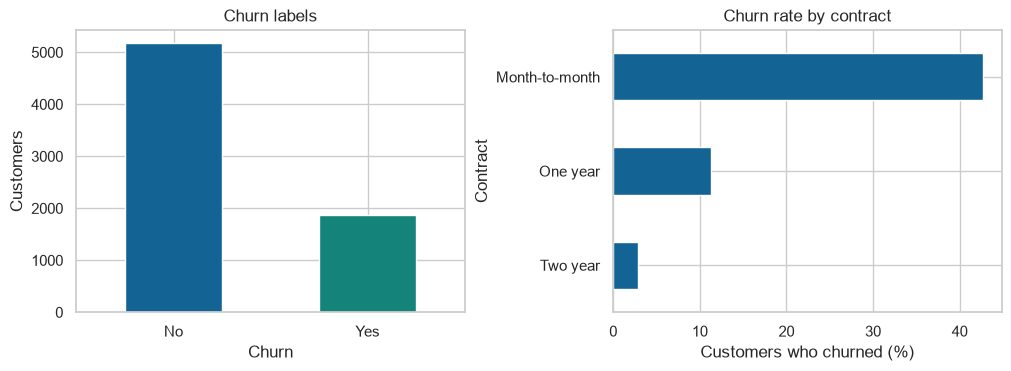

In [4]:
outcomes = data["Churn"].value_counts().reindex(["No", "Yes"])
contracts = labeled.groupby("Contract")["churned"].agg(customers="size", churn_rate="mean")
display(outcomes.rename("Customers").to_frame())
display(contracts.style.format({"churn_rate": "{:.1%}"}))
print(f"Overall churn rate: {labeled['churned'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
outcomes.plot.bar(ax=axes[0], color=["#136495", "#148379"], rot=0, title="Churn labels")
axes[0].set_ylabel("Customers")
(100 * contracts["churn_rate"]).sort_values().plot.barh(
    ax=axes[1], color="#136495", title="Churn rate by contract"
)
axes[1].set_xlabel("Customers who churned (%)")
plt.show()

## Monthly charges and tenure

Use a box plot to compare monthly charges across outcomes. Show tenure as a within-group percentage because fewer customers churned.

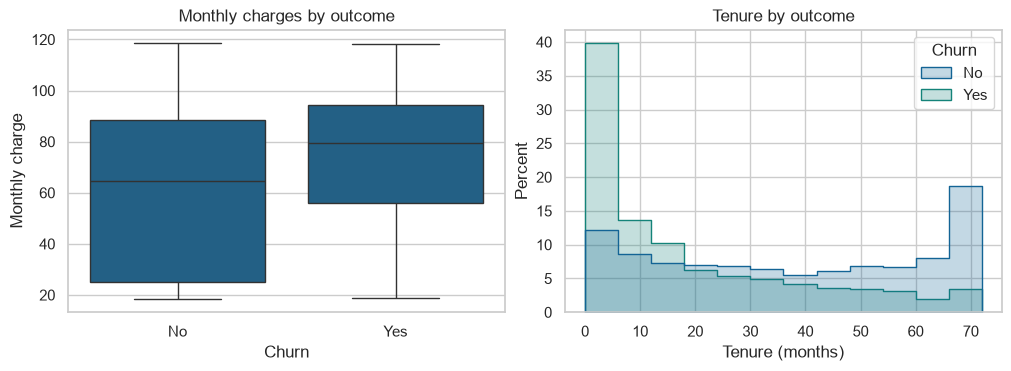

,MonthlyCharges,tenure
Churn,,
No,64.425,38.0
Yes,79.650,10.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
sns.boxplot(data=data, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[0])
axes[0].set(title="Monthly charges by outcome", ylabel="Monthly charge")
sns.histplot(data=data, x="tenure", hue="Churn", bins=12, stat="percent",
             common_norm=False, element="step", ax=axes[1])
axes[1].set(title="Tenure by outcome", xlabel="Tenure (months)")
plt.show()
display(data.groupby("Churn")[["MonthlyCharges", "tenure"]].median())

## Service usage and correlations

Group sizes provide context for service-level churn rates. The heatmap uses Pearson correlation for the three quantitative inputs and the binary outcome. Pearson correlation describes linear association and can miss nonlinear patterns.

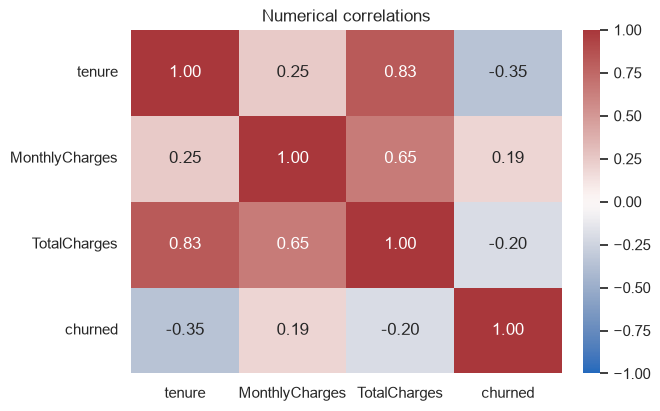

In [6]:
service_fields = ["PhoneService", "InternetService", "OnlineSecurity", "TechSupport",
                  "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
service_rates = pd.concat({
    field: labeled.groupby(field)["churned"].agg(customers="size", churn_rate="mean")
    for field in service_fields
}, names=["Service", "Subscription"])
display(service_rates.style.format({"churn_rate": "{:.1%}"}))
correlations = labeled[["tenure", "MonthlyCharges", "TotalCharges", "churned"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 4), layout="constrained")
sns.heatmap(correlations, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax)
ax.set_title("Numerical correlations")
plt.show()

## What to say in an interview

The sample describes one fictional provider. Different customer groups can have different contracts, prices, and service combinations at the same time. Treat the comparisons as associations. A hypothesis about retention would need a separate causal study or experiment. A random holdout measures performance on the same sample distribution and gives no evidence about future time periods by itself.

In [7]:
highest = contracts["churn_rate"].idxmax()
lowest = contracts["churn_rate"].idxmin()
tenure_medians = data.groupby("Churn")["tenure"].median()
charge_medians = data.groupby("Churn")["MonthlyCharges"].median()
display(Markdown(
    f"- Overall recorded churn was **{labeled['churned'].mean():.1%}**.\n"
    f"- **{highest}** contracts had the highest recorded churn rate "
    f"(**{contracts.loc[highest, 'churn_rate']:.1%}**) and **{lowest}** the lowest "
    f"(**{contracts.loc[lowest, 'churn_rate']:.1%}**).\n"
    f"- Median tenure was **{tenure_medians['Yes']:.0f} months** among churners "
    f"and **{tenure_medians['No']:.0f} months** among retained customers.\n"
    f"- Median monthly charges were **${charge_medians['Yes']:.2f}** for churners "
    f"and **${charge_medians['No']:.2f}** for retained customers."
))

- Overall recorded churn was **26.5%**.
- **Month-to-month** contracts had the highest recorded churn rate (**42.7%**) and **Two year** the lowest (**2.8%**).
- Median tenure was **10 months** among churners and **38 months** among retained customers.
- Median monthly charges were **$79.65** for churners and **$64.43** for retained customers.